# Module 07 — Moving Beyond Linearity

**Applied exercises only** · ISLP, Chapter 7

**Printed textbook pages:** 327–329 (exercise starting pages)  

In [1]:
# Common imports and data loading: run this cell once before starting the exercises.
# All data sets come from the ISLP package installed in the project's .venv.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm
from statsmodels.nonparametric.smoothers_lowess import lowess
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import KFold, cross_val_score, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler, KBinsDiscretizer
from pygam import LinearGAM, s as gam_s, f as gam_f
from ISLP import load_data

rng = np.random.default_rng(1)

Wage = load_data("Wage")
Auto = load_data("Auto")
Boston = load_data("Boston")
College = load_data("College")
College.columns = College.columns.str.replace(".", "_", regex=False)  # formula-friendly names

print(f"Loaded Wage {Wage.shape}, Auto {Auto.shape}, Boston {Boston.shape}, and College {College.shape} from ISLP.")

Loaded Wage (3000, 11), Auto (392, 8), Boston (506, 13), and College (777, 18) from ISLP.


---

## Exercise 6 · Applied

**Textbook: printed page 327**

In this exercise, you will further analyze the Wage data set considered
throughout this chapter.

### Exercise 6(a)

Perform polynomial regression to predict wage using age. Use
cross-validation to select the optimal degree d for the polynomial. What degree was chosen, and how does this compare to
the results of hypothesis testing using ANOVA? Make a plot of
the resulting polynomial fit to the data.

Cross-validation MSE by polynomial degree:
1     1677.205
2     1601.356
3     1596.246
4     1601.204
5     1611.725
6     1626.927
7     1644.366
8     1661.580
9     1676.952
10    1689.811

The minimum CV error selects degree 3 (MSE=1596.246).

Nested-model ANOVA for degrees 1 through 5:
   df_resid           ssr  df_diff      ss_diff         F  Pr(>F)
0    2998.0  5.022216e+06      0.0          NaN       NaN     NaN
1    2997.0  4.793430e+06      1.0  228786.0101  143.5931  0.0000
2    2996.0  4.777674e+06      1.0   15755.6937    9.8888  0.0017
3    2995.0  4.771604e+06      1.0    6070.1521    3.8098  0.0510
4    2994.0  4.770322e+06      1.0    1282.5630    0.8050  0.3697


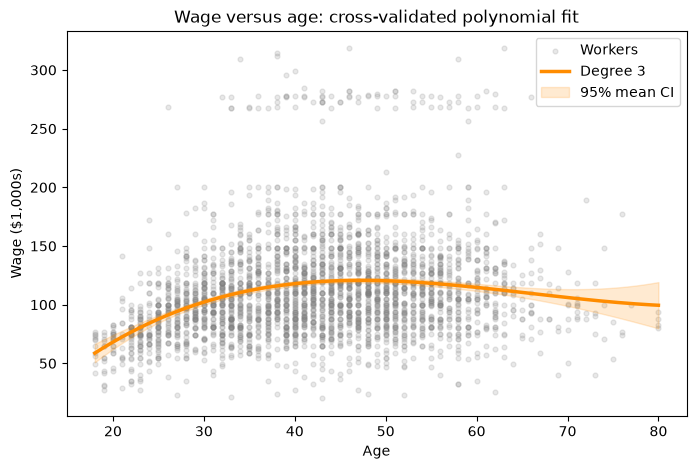

The curve is nonlinear: wages rise through much of early and middle adulthood, then flatten or decline at older ages. ANOVA tests whether each added degree improves fit; CV instead evaluates predictive error on held-out folds.


In [2]:
# Exercise 6(a): select a polynomial degree by 10-fold cross-validation.
from sklearn.pipeline import make_pipeline

X_age = Wage[["age"]]
y_wage = Wage["wage"]
cv = KFold(n_splits=10, shuffle=True, random_state=1)
poly_cv = {}
for degree in range(1, 11):
    model = make_pipeline(PolynomialFeatures(degree=degree, include_bias=False), LinearRegression())
    mse = -cross_val_score(model, X_age, y_wage, cv=cv, scoring="neg_mean_squared_error").mean()
    poly_cv[degree] = mse

cv_results = pd.Series(poly_cv, name="10-fold CV MSE")
best_degree = int(cv_results.idxmin())
print("Cross-validation MSE by polynomial degree:")
print(cv_results.round(3).to_string())
print(f"\nThe minimum CV error selects degree {best_degree} (MSE={cv_results[best_degree]:.3f}).")

# Compare nested polynomial models with ANOVA, as a hypothesis-testing check.
formula = lambda degree: "wage ~ " + " + ".join(
    ["age"] + [f"I(age ** {power})" for power in range(2, degree + 1)]
)
poly_models = [smf.ols(formula(degree), data=Wage).fit() for degree in range(1, 6)]
print("\nNested-model ANOVA for degrees 1 through 5:")
print(anova_lm(*poly_models).round(4))

best_poly_fit = smf.ols(formula(best_degree), data=Wage).fit()
age_grid = np.linspace(Wage["age"].min(), Wage["age"].max(), 250)
prediction = best_poly_fit.get_prediction(pd.DataFrame({"age": age_grid})).summary_frame()
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(Wage["age"], y_wage, s=12, alpha=0.18, color="gray", label="Workers")
ax.plot(age_grid, prediction["mean"], color="darkorange", linewidth=2.5, label=f"Degree {best_degree}")
ax.fill_between(age_grid, prediction["mean_ci_lower"], prediction["mean_ci_upper"], color="darkorange", alpha=0.18, label="95% mean CI")
ax.set(title="Wage versus age: cross-validated polynomial fit", xlabel="Age", ylabel="Wage ($1,000s)")
ax.legend()
plt.show()
print("The curve is nonlinear: wages rise through much of early and middle adulthood, then flatten or decline at older ages. ANOVA tests whether each added degree improves fit; CV instead evaluates predictive error on held-out folds.")

### Exercise 6(b)

Fit a step function to predict wage using age, and perform crossvalidation to choose the optimal number of cuts. Make a plot of
the fit obtained.

Cross-validation MSE by number of age bins:
2     1699.733
3     1659.288
4     1636.026
5     1640.337
6     1623.226
7     1621.008
8     1614.997
9     1616.374
10    1615.653
11    1609.406
12    1609.505
13    1610.876
14    1606.755
15    1609.552

Selected 14 bins (MSE=1606.755).


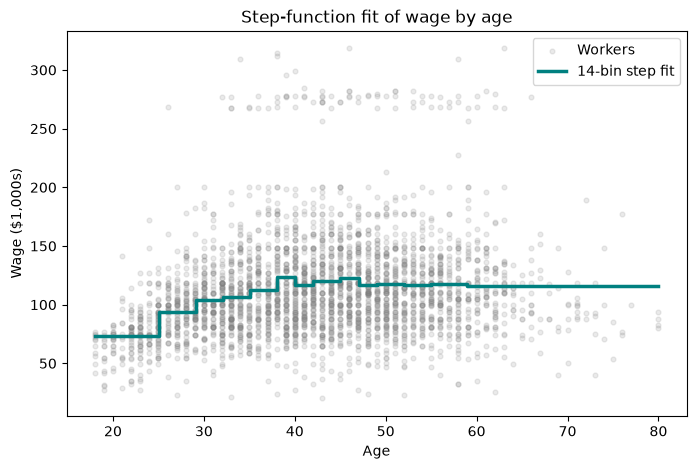

The step model estimates a separate mean wage within each age interval. Its flat segments make abrupt changes at cut points; cross-validation balances this flexibility against overfitting.


In [3]:
# Exercise 6(b): compare quantile-based step functions with 10-fold CV.
step_cv = {}
for n_bins in range(2, 16):
    step_model = make_pipeline(
        KBinsDiscretizer(n_bins=n_bins, encode="onehot-dense", strategy="quantile"),
        LinearRegression(),
    )
    step_cv[n_bins] = -cross_val_score(
        step_model, X_age, y_wage, cv=cv, scoring="neg_mean_squared_error"
    ).mean()

step_cv_results = pd.Series(step_cv, name="10-fold CV MSE")
best_bins = int(step_cv_results.idxmin())
best_step_model = make_pipeline(
    KBinsDiscretizer(n_bins=best_bins, encode="onehot-dense", strategy="quantile"),
    LinearRegression(),
).fit(X_age, y_wage)
print("Cross-validation MSE by number of age bins:")
print(step_cv_results.round(3).to_string())
print(f"\nSelected {best_bins} bins (MSE={step_cv_results[best_bins]:.3f}).")

step_prediction = best_step_model.predict(pd.DataFrame({"age": age_grid}))
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(Wage["age"], y_wage, s=12, alpha=0.16, color="gray", label="Workers")
ax.step(age_grid, step_prediction, where="mid", color="teal", linewidth=2.5, label=f"{best_bins}-bin step fit")
ax.set(title="Step-function fit of wage by age", xlabel="Age", ylabel="Wage ($1,000s)")
ax.legend()
plt.show()
print("The step model estimates a separate mean wage within each age interval. Its flat segments make abrupt changes at cut points; cross-validation balances this flexibility against overfitting.")

**Observations / conclusions**

- **(a)** 10-fold CV picks a **degree-3** polynomial (CV MSE 1596). Degrees 2–4 are within ~5 units of each other. The nested ANOVA agrees: degree 2 clearly improves on linear (p < 0.0001), degree 3 still helps (p = 0.0017), degree 4 is borderline (p = 0.051), and degree 5 adds nothing (p = 0.37). Both approaches favour a cubic (or possibly quadratic) curve. Wage rises until roughly age 45–50 and then declines.
- **(b)** For step functions, CV error falls quickly up to about 6–8 bins and is nearly flat after that. The minimum is at 14 bins (1607), but anything from 8 to 15 bins is practically tied. The step fit traces the same rise-then-fall shape as the polynomial, just less smoothly.

---

## Exercise 7 · Applied

**Textbook: printed page 327**

The Wage data set contains a number of other features not explored
in this chapter, such as marital status (maritl), job class (jobclass),
and others. Explore the relationships between some of these other
predictors and wage, and use non-linear fitting techniques in order to
fit flexible models to the data. Create plots of the results obtained,
and write a summary of your findings.

Median wage by job class:
jobclass
1. Industrial      99.7
2. Information    112.6

Median wage by marital status (ordered by median):
maritl
1. Never Married     88.0
5. Separated         95.2
4. Divorced          99.7
3. Widowed          104.9
2. Married          112.6


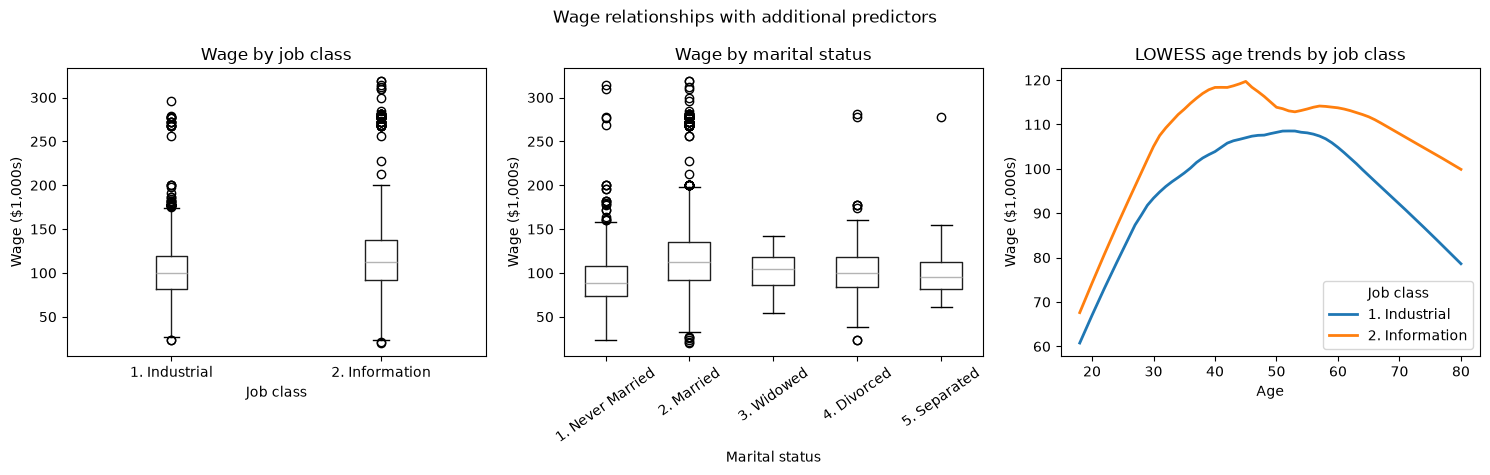


Nested-model test for adding a 5-df spline in age:
   df_resid           ssr  df_diff      ss_diff        F  Pr(>F)
0    2994.0  4.654752e+06      0.0          NaN      NaN     NaN
1    2989.0  4.475536e+06      5.0  179216.7987  23.9381     0.0
Flexible model R-squared: 0.143
Wage varies appreciably across job class and marital-status groups. The LOWESS curves also bend with age and differ between job classes; the nested-model test quantifies whether a flexible age effect improves fit beyond those categories.


In [4]:
# Exercise 7: compare wage across categories and fit a flexible age effect.
print("Median wage by job class:")
print(Wage.groupby("jobclass", observed=True)["wage"].median().round(1).to_string())
print("\nMedian wage by marital status (ordered by median):")
print(Wage.groupby("maritl", observed=True)["wage"].median().sort_values().round(1).to_string())

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
Wage.boxplot(column="wage", by="jobclass", ax=axes[0], grid=False)
axes[0].set(title="Wage by job class", xlabel="Job class", ylabel="Wage ($1,000s)")
Wage.boxplot(column="wage", by="maritl", ax=axes[1], grid=False, rot=35)
axes[1].set(title="Wage by marital status", xlabel="Marital status", ylabel="Wage ($1,000s)")
for label, group in Wage.groupby("jobclass", observed=True):
    smooth = lowess(group["wage"], group["age"], frac=0.35, return_sorted=True)
    axes[2].plot(smooth[:, 0], smooth[:, 1], linewidth=2, label=label)
axes[2].set(title="LOWESS age trends by job class", xlabel="Age", ylabel="Wage ($1,000s)")
axes[2].legend(title="Job class")
fig.suptitle("Wage relationships with additional predictors")
fig.tight_layout()
plt.show()

categorical_fit = smf.ols("wage ~ C(jobclass) + C(maritl)", data=Wage).fit()
flexible_fit = smf.ols("wage ~ C(jobclass) + C(maritl) + bs(age, df=5)", data=Wage).fit()
print("\nNested-model test for adding a 5-df spline in age:")
print(anova_lm(categorical_fit, flexible_fit).round(4))
print(f"Flexible model R-squared: {flexible_fit.rsquared:.3f}")
print("Wage varies appreciably across job class and marital-status groups. The LOWESS curves also bend with age and differ between job classes; the nested-model test quantifies whether a flexible age effect improves fit beyond those categories.")

**Observations / conclusions**

Information-sector jobs pay more than industrial jobs (median 112.6 vs 99.7, in \$1,000s). Married workers have the highest median wage (112.6), and never-married workers have the lowest (88.0). This is partly an age effect, since never-married workers are younger. The LOWESS curves show the same nonlinear rise-and-plateau in age for both job classes, with Information consistently higher.
Adding a 5-df B-spline in `age` to a model that already has `jobclass` and `maritl` is highly significant (F = 23.9, p < 0.001). Even so, the full model explains only $R^2 \approx 0.14$ of the variation in wage, so most of the variation is not explained by these variables.

---

## Exercise 8 · Applied

**Textbook: printed page 327**

Fit some of the non-linear models investigated in this chapter to the
Auto data set. Is there evidence for non-linear relationships in this
data set? Create some informative plots to justify your answer.

Nested polynomial-model ANOVA for mpg versus horsepower:
   df_resid        ssr  df_diff    ss_diff         F  Pr(>F)
0     390.0  9385.9159      0.0        NaN       NaN     NaN
1     389.0  7442.0294      1.0  1943.8865  103.8767  0.0000
2     388.0  7426.4360      1.0    15.5934    0.8333  0.3619
3     387.0  7399.5226      1.0    26.9134    1.4382  0.2312
4     386.0  7223.3717      1.0   176.1509    9.4131  0.0023

Quadratic model summary:
                            OLS Regression Results                            
Dep. Variable:                    mpg   R-squared:                       0.688
Model:                            OLS   Adj. R-squared:                  0.686
Method:                 Least Squares   F-statistic:                     428.0
Date:                Wed, 21 Oct 2026   Prob (F-statistic):           5.40e-99
Time:                        17:36:47   Log-Likelihood:                -1133.2
No. Observations:                 392   AIC:                             2272

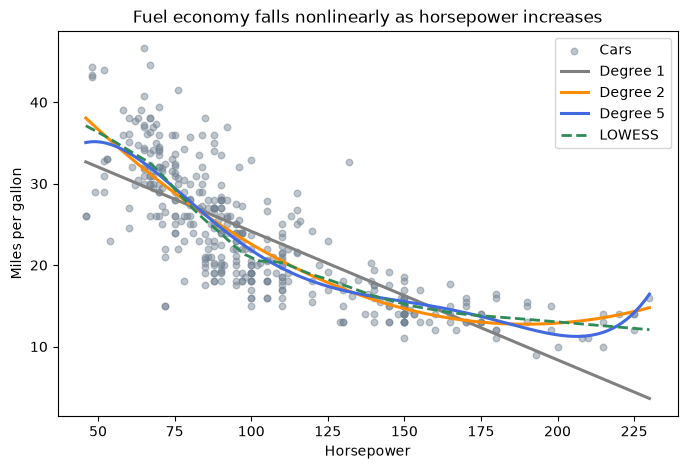

The scatter and smooth fits show a steep decline in mpg at low-to-moderate horsepower that levels at higher horsepower. The nested ANOVA indicates that higher-order terms improve on a straight line, supporting a nonlinear relationship.


In [5]:
# Exercise 8: examine a strongly nonlinear predictor-response relationship in Auto.
Auto_formula = lambda degree: "mpg ~ " + " + ".join(
    ["horsepower"] + [f"I(horsepower ** {power})" for power in range(2, degree + 1)]
)
auto_poly_models = [smf.ols(Auto_formula(degree), data=Auto).fit() for degree in range(1, 6)]
print("Nested polynomial-model ANOVA for mpg versus horsepower:")
print(anova_lm(*auto_poly_models).round(4))
print("\nQuadratic model summary:")
print(auto_poly_models[1].summary())

hp_grid = np.linspace(Auto["horsepower"].min(), Auto["horsepower"].max(), 250)
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(Auto["horsepower"], Auto["mpg"], alpha=0.45, s=22, color="slategray", label="Cars")
for degree, color in [(1, "gray"), (2, "darkorange"), (5, "royalblue")]:
    fitted = auto_poly_models[degree - 1].predict(pd.DataFrame({"horsepower": hp_grid}))
    ax.plot(hp_grid, fitted, color=color, linewidth=2.2, label=f"Degree {degree}")
ax.plot(*lowess(Auto["mpg"], Auto["horsepower"], frac=0.35, return_sorted=True).T, color="seagreen", linewidth=2, linestyle="--", label="LOWESS")
ax.set(title="Fuel economy falls nonlinearly as horsepower increases", xlabel="Horsepower", ylabel="Miles per gallon")
ax.legend()
plt.show()
print("The scatter and smooth fits show a steep decline in mpg at low-to-moderate horsepower that levels at higher horsepower. The nested ANOVA indicates that higher-order terms improve on a straight line, supporting a nonlinear relationship.")

**Observations / conclusions**

There is strong evidence of non-linearity between `mpg` and `horsepower`. Going from a linear to a quadratic fit reduces RSS from 9,386 to 7,442 (F = 104, p < 0.0001), and $R^2$ rises to 0.69. The cubic and quartic terms add nothing (p = 0.36, 0.23). The 5th-degree term is significant (p = 0.002), but it mostly adds a wiggle at the extremes. The LOWESS curve follows the quadratic closely: mpg drops steeply at low horsepower and levels off above ~150 hp.

---

## Exercise 9 · Applied

**Textbook: printed page 327**

This question uses the variables dis (the weighted mean of distances
to five Boston employment centers) and nox (nitrogen oxides concentration in parts per 10 million) from the Boston data. We will treat
dis as the predictor and nox as the response.

### Exercise 9(a)

Use the poly() function from the ISLP.models module to fit a
cubic polynomial regression to predict nox using dis. Report the
regression output, and plot the resulting data and polynomial
fits.

                            OLS Regression Results                            
Dep. Variable:                    nox   R-squared:                       0.715
Model:                            OLS   Adj. R-squared:                  0.713
Method:                 Least Squares   F-statistic:                     419.3
Date:                Wed, 21 Oct 2026   Prob (F-statistic):          2.71e-136
Time:                        17:36:47   Log-Likelihood:                 690.44
No. Observations:                 506   AIC:                            -1373.
Df Residuals:                     502   BIC:                            -1356.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept       0.9341      0.021     45.110      

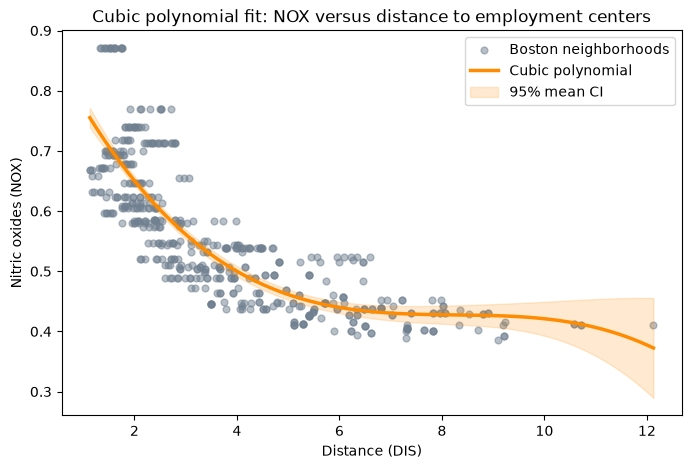

The fitted NOX concentration drops sharply with DIS at shorter distances and then tapers off, indicating a nonlinear association.


In [6]:
# Exercise 9(a): cubic polynomial regression for Boston nitric-oxide concentration.
cubic_nox = smf.ols("nox ~ dis + I(dis ** 2) + I(dis ** 3)", data=Boston).fit()
print(cubic_nox.summary())
dis_grid = np.linspace(Boston["dis"].min(), Boston["dis"].max(), 300)
cubic_prediction = cubic_nox.get_prediction(pd.DataFrame({"dis": dis_grid})).summary_frame()
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(Boston["dis"], Boston["nox"], s=24, alpha=0.5, color="slategray", label="Boston neighborhoods")
ax.plot(dis_grid, cubic_prediction["mean"], color="darkorange", linewidth=2.5, label="Cubic polynomial")
ax.fill_between(dis_grid, cubic_prediction["mean_ci_lower"], cubic_prediction["mean_ci_upper"], color="darkorange", alpha=0.18, label="95% mean CI")
ax.set(title="Cubic polynomial fit: NOX versus distance to employment centers", xlabel="Distance (DIS)", ylabel="Nitric oxides (NOX)")
ax.legend()
plt.show()
print("The fitted NOX concentration drops sharply with DIS at shorter distances and then tapers off, indicating a nonlinear association.")

### Exercise 9(b)

Plot the polynomial fits for a range of different polynomial
degrees (say, from 1 to 10), and report the associated residual
sum of squares.

Polynomial degree and training RSS:
1     2.769
2     2.035
3     1.934
4     1.933
5     1.915
6     1.878
7     1.849
8     1.836
9     1.833
10    1.832


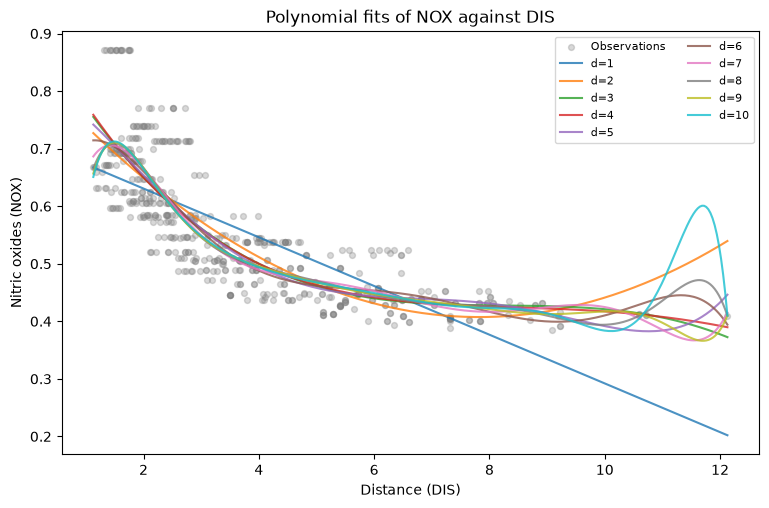

Training RSS cannot increase as polynomial degree rises because each higher-degree model contains the lower-degree model; cross-validation is needed to assess predictive performance.


In [7]:
# Exercise 9(b): compare polynomial degrees 1–10 by in-sample RSS.
poly_dis_models = {}
poly_dis_rss = {}
for degree in range(1, 11):
    model = make_pipeline(
        StandardScaler(),
        PolynomialFeatures(degree=degree, include_bias=False),
        LinearRegression(),
    ).fit(Boston[["dis"]], Boston["nox"])
    poly_dis_models[degree] = model
    residual = Boston["nox"] - model.predict(Boston[["dis"]])
    poly_dis_rss[degree] = float(np.sum(residual**2))

print("Polynomial degree and training RSS:")
print(pd.Series(poly_dis_rss, name="RSS").round(3).to_string())
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.scatter(Boston["dis"], Boston["nox"], s=18, alpha=0.3, color="gray", label="Observations")
for degree, model in poly_dis_models.items():
    ax.plot(dis_grid, model.predict(pd.DataFrame({"dis": dis_grid})), linewidth=1.5, alpha=0.8, label=f"d={degree}")
ax.set(title="Polynomial fits of NOX against DIS", xlabel="Distance (DIS)", ylabel="Nitric oxides (NOX)")
ax.legend(ncol=2, fontsize=8)
plt.show()
print("Training RSS cannot increase as polynomial degree rises because each higher-degree model contains the lower-degree model; cross-validation is needed to assess predictive performance.")

### Exercise 9(c)

Perform cross-validation or another approach to select the optimal degree for the polynomial, and explain your results.

Cross-validation MSE by polynomial degree:
1     0.00553
2     0.00409
3     0.00386
4     0.00390
5     0.00417
6     0.00664
7     0.01460
8     0.00720
9     0.00552
10    0.00683

The selected degree is 3; its mean CV MSE is 0.00386.


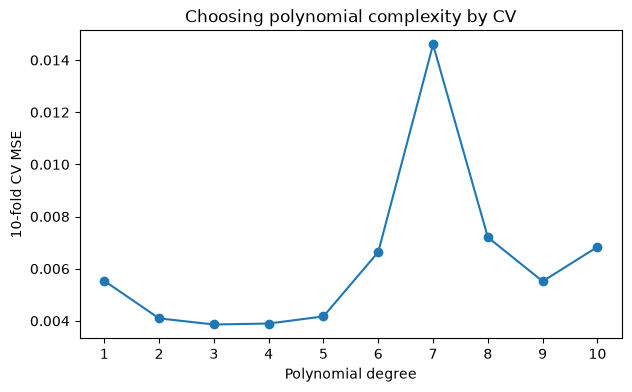

Unlike training RSS, CV error penalizes models that extrapolate or fluctuate too much. The best degree is the one with the lowest mean held-out MSE; nearby degrees with similar errors should be viewed as practically comparable.


In [8]:
# Exercise 9(c): select the polynomial degree by shuffled 10-fold CV.
boston_cv = KFold(n_splits=10, shuffle=True, random_state=7)
poly_dis_cv = {}
for degree in range(1, 11):
    model = make_pipeline(
        StandardScaler(),
        PolynomialFeatures(degree=degree, include_bias=False),
        LinearRegression(),
    )
    poly_dis_cv[degree] = -cross_val_score(
        model, Boston[["dis"]], Boston["nox"], cv=boston_cv, scoring="neg_mean_squared_error"
    ).mean()

poly_cv_series = pd.Series(poly_dis_cv, name="10-fold CV MSE")
best_poly_dis_degree = int(poly_cv_series.idxmin())
print("Cross-validation MSE by polynomial degree:")
print(poly_cv_series.round(5).to_string())
print(f"\nThe selected degree is {best_poly_dis_degree}; its mean CV MSE is {poly_cv_series[best_poly_dis_degree]:.5f}.")
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(poly_cv_series.index, poly_cv_series.values, marker="o")
ax.set(title="Choosing polynomial complexity by CV", xlabel="Polynomial degree", ylabel="10-fold CV MSE", xticks=range(1, 11))
plt.show()
print("Unlike training RSS, CV error penalizes models that extrapolate or fluctuate too much. The best degree is the one with the lowest mean held-out MSE; nearby degrees with similar errors should be viewed as practically comparable.")

### Exercise 9(d)

Use the bs() function from the ISLP.models module to fit a regression spline to predict nox using dis. Report the output for
the fit using four degrees of freedom. How did you choose the
knots? Plot the resulting fit.

                            OLS Regression Results                            
Dep. Variable:                    nox   R-squared:                       0.716
Model:                            OLS   Adj. R-squared:                  0.714
Method:                 Least Squares   F-statistic:                     316.5
Date:                Wed, 21 Oct 2026   Prob (F-statistic):          1.39e-135
Time:                        17:36:47   Log-Likelihood:                 691.93
No. Observations:                 506   AIC:                            -1374.
Df Residuals:                     501   BIC:                            -1353.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                                 coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------
Intercept           

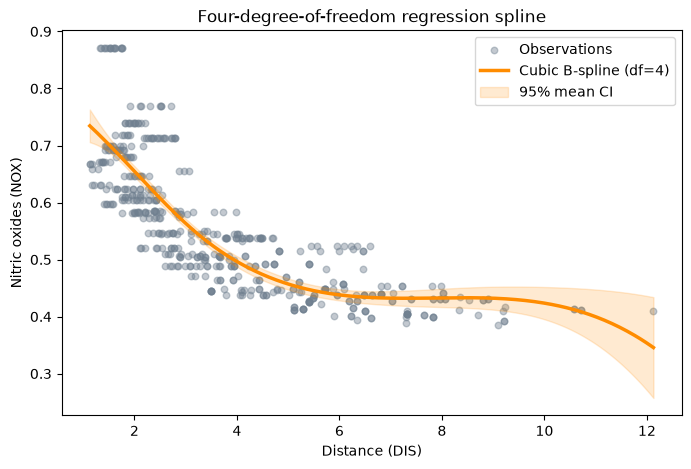

Patsy's bs() constructs a cubic B-spline basis; with no knots specified, its internal knots are placed at data quantiles. Boundary knots are set from the observed predictor range.


In [9]:
# Exercise 9(d): cubic B-spline basis with four basis degrees of freedom.
spline4 = smf.ols("nox ~ bs(dis, df=4, degree=3)", data=Boston).fit()
print(spline4.summary())
spline4_prediction = spline4.get_prediction(pd.DataFrame({"dis": dis_grid})).summary_frame()
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(Boston["dis"], Boston["nox"], s=22, alpha=0.42, color="slategray", label="Observations")
ax.plot(dis_grid, spline4_prediction["mean"], color="darkorange", linewidth=2.5, label="Cubic B-spline (df=4)")
ax.fill_between(dis_grid, spline4_prediction["mean_ci_lower"], spline4_prediction["mean_ci_upper"], color="darkorange", alpha=0.18, label="95% mean CI")
ax.set(title="Four-degree-of-freedom regression spline", xlabel="Distance (DIS)", ylabel="Nitric oxides (NOX)")
ax.legend()
plt.show()
print("Patsy's bs() constructs a cubic B-spline basis; with no knots specified, its internal knots are placed at data quantiles. Boundary knots are set from the observed predictor range.")

### Exercise 9(e)

Now fit a regression spline for a range of degrees of freedom, and
plot the resulting fits and report the resulting RSS. Describe the
results obtained.

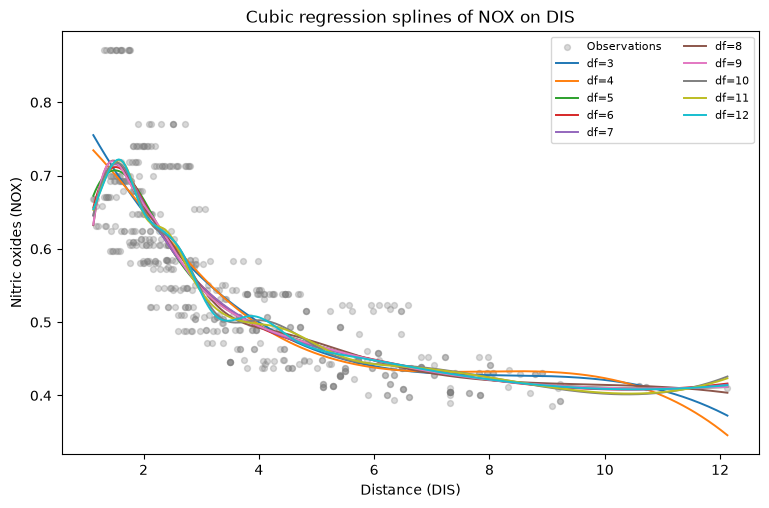

Training RSS by spline degrees of freedom:
3     1.9341
4     1.9228
5     1.8402
6     1.8340
7     1.8299
8     1.8170
9     1.8257
10    1.7925
11    1.7970
12    1.7890


In [10]:
# Exercise 9(e): regression splines for a range of degrees of freedom.
spline_rss = {}
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.scatter(Boston["dis"], Boston["nox"], s=18, alpha=0.3, color="gray", label="Observations")
for df in range(3, 13):
    fit = smf.ols(f"nox ~ bs(dis, df={df}, degree=3)", data=Boston).fit()
    spline_rss[df] = fit.ssr
    ax.plot(dis_grid, fit.predict(pd.DataFrame({"dis": dis_grid})), linewidth=1.4, label=f"df={df}")
ax.set(title="Cubic regression splines of NOX on DIS", xlabel="Distance (DIS)", ylabel="Nitric oxides (NOX)")
ax.legend(ncol=2, fontsize=8)
plt.show()
print("Training RSS by spline degrees of freedom:")
print(pd.Series(spline_rss, name="RSS").round(4).to_string())

### Exercise 9(f)

Perform cross-validation or another approach in order to select
the best degrees of freedom for a regression spline on this data.
Describe your results.

3     0.003860
4     0.003888
5     0.003706
6     0.003716
7     0.003717
8     0.003739
9     0.003756
10    0.003698
11    0.003709
12    0.003709
13    0.003716
14    0.003748
15    0.003762

CV selects df = 10 (CV MSE 0.003698).


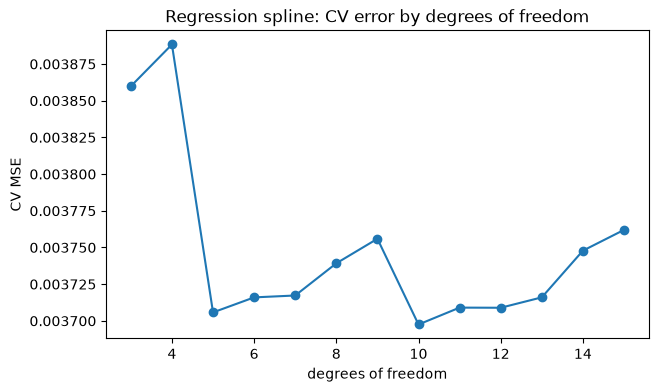

In [11]:
# Exercise 9(f): choose spline degrees of freedom by 10-fold CV.
# Knot positions are fixed from the full data (bs() boundary knots) so held-out folds never fall
# outside the spline's range; the fit itself only uses the training folds.
from patsy import dmatrix

spline_cv = {}
for df in range(3, 16):
    fold_mse = []
    for tr_idx, te_idx in boston_cv.split(Boston):
        tr, te = Boston.iloc[tr_idx], Boston.iloc[te_idx]
        knots = np.quantile(tr["dis"], np.linspace(0, 1, df - 3 + 2)[1:-1])
        lb, ub = Boston["dis"].min(), Boston["dis"].max()
        basis = lambda d: dmatrix(f"bs(x, knots=knots, degree=3, lower_bound={lb}, upper_bound={ub})",
                                  {"x": d["dis"], "knots": knots}, return_type="dataframe")
        model = sm.OLS(tr["nox"], basis(tr)).fit()
        fold_mse.append(np.mean((te["nox"] - model.predict(basis(te)))**2))
    spline_cv[df] = np.mean(fold_mse)

spline_cv = pd.Series(spline_cv, name="10-fold CV MSE")
best_spline_df = int(spline_cv.idxmin())
print(spline_cv.round(6).to_string())
print(f"\nCV selects df = {best_spline_df} (CV MSE {spline_cv[best_spline_df]:.6f}).")
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(spline_cv.index, spline_cv.values, marker="o")
ax.set(title="Regression spline: CV error by degrees of freedom", xlabel="degrees of freedom", ylabel="CV MSE")
plt.show()

**Observations / conclusions**

- **(a)** The cubic fit of `nox` on `dis` has all terms significant ($R^2$ = 0.715). NOX falls steeply as distance to employment centres increases and then flattens.
- **(b)** Training RSS falls as the degree increases (from 2.77 at degree 1 to about 1.83 at degree 10), as it must.
- **(c)** 10-fold CV selects **degree 3** (CV MSE 0.00386). Degree 4 is almost the same. Degrees ≥ 6 blow up because high-degree polynomials behave wildly at the edges of the `dis` range.
- **(d)** With `df = 4`, `bs()` builds a cubic spline with one interior knot at the **median** of `dis` (≈ 3.2). Boundary knots are at the min and max. The fit looks almost identical to the cubic polynomial ($R^2$ = 0.716).
- **(e)** Spline training RSS generally decreases with df (1.93 at df = 3 to 1.79 at df = 12). It is not strictly monotone, because changing df also moves the quantile-based knots, so the models are not nested.
- **(f)** CV error is nearly flat from df = 5 to df = 13 (≈ 0.00370–0.00376). The minimum is at df = 10 (0.003698), but **df = 5** (0.003706) is practically identical and much simpler. I'd choose df ≈ 5. In any case, a smooth curve with only a few degrees of freedom is enough.

---

## Exercise 10 · Applied

**Textbook: printed page 328**

This question relates to the College data set.

### Exercise 10(a)

Split the data into a training set and a test set. Using out-of-state
tuition as the response and the other variables as the predictors,
perform forward stepwise selection on the training set in order
to identify a satisfactory model that uses just a subset of the
predictors.

Order variables enter: ['Room_Board', 'perc_alumni', 'Expend', 'Private', 'PhD', 'Grad_Rate', 'Personal', 'Top25perc', 'Accept', 'Apps', 'Enroll', 'Top10perc', 'S_F_Ratio', 'Terminal', 'Books', 'P_Undergrad', 'F_Undergrad']
CV minimum at 10 variables; choose 7 (within 1% of minimum):
['Room_Board', 'perc_alumni', 'Expend', 'Private', 'PhD', 'Grad_Rate', 'Personal']


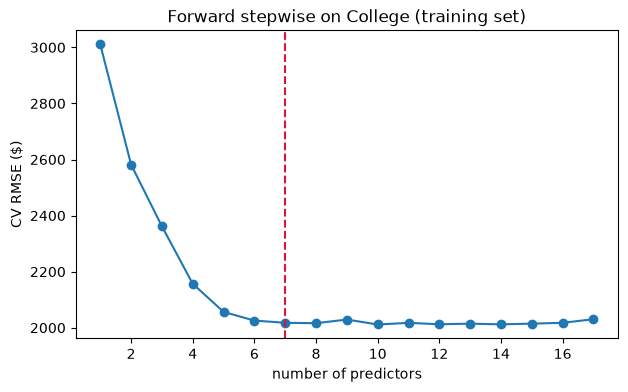

In [12]:
# Exercise 10(a): forward stepwise selection on the training set; model size chosen by 10-fold CV.
College["Private"] = (College["Private"] == "Yes").astype(int) if College["Private"].dtype != int else College["Private"]
predictors_c = [c for c in College.columns if c != "Outstate"]
C_train, C_test = train_test_split(College, test_size=0.3, random_state=1)

def ols_rss(cols, data):
    return smf.ols("Outstate ~ " + (" + ".join(cols) if cols else "1"), data=data).fit().ssr

path_c, current = {}, []
for k in range(1, len(predictors_c) + 1):
    best = min((c for c in predictors_c if c not in current), key=lambda c: ols_rss(current + [c], C_train))
    current = current + [best]
    path_c[k] = list(current)

cv_c = KFold(10, shuffle=True, random_state=1)
fwd_cv = pd.Series({
    k: -cross_val_score(LinearRegression(), C_train[cols], C_train["Outstate"], cv=cv_c,
                        scoring="neg_mean_squared_error").mean()
    for k, cols in path_c.items()
}, name="CV MSE")
# One-standard-error-style choice: smallest model within 1% of the minimum CV error.
k_sel = int(fwd_cv[fwd_cv <= fwd_cv.min() * 1.01].index.min())
selected = path_c[k_sel]
print("Order variables enter:", path_c[len(predictors_c)])
print(f"CV minimum at {int(fwd_cv.idxmin())} variables; choose {k_sel} (within 1% of minimum):")
print(selected)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(fwd_cv.index, np.sqrt(fwd_cv.values), marker="o")
ax.axvline(k_sel, color="crimson", ls="--")
ax.set(title="Forward stepwise on College (training set)", xlabel="number of predictors", ylabel="CV RMSE ($)")
plt.show()

### Exercise 10(b)

Fit a GAM on the training data, using out-of-state tuition as
the response and the features selected in the previous step as
the predictors. Plot the results, and explain your findings.

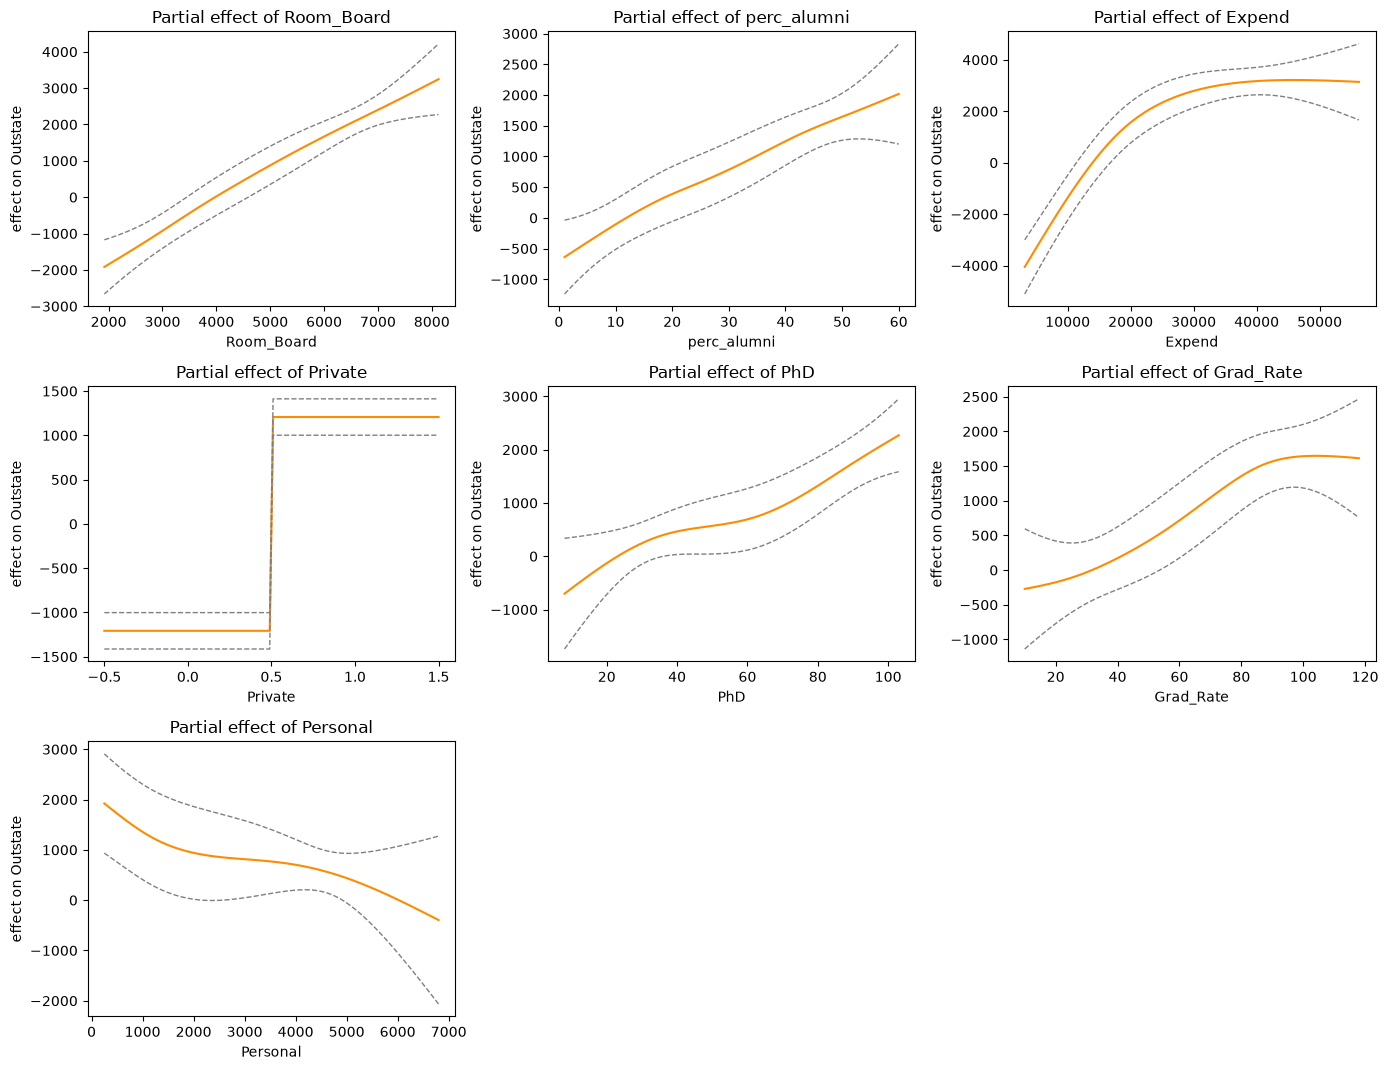

LinearGAM                                                                                                 
=============================================== ==========================================================
Distribution:                        NormalDist Effective DoF:                                     17.2482
Link Function:                     IdentityLink Log Likelihood:                                 -4857.7896
Number of Samples:                          543 AIC:                                             9752.0754
                                                AICc:                                            9753.4167
                                                GCV:                                          3779103.8566
                                                Scale:                                           1887.7656
                                                Pseudo R-Squared:                                   0.7842
Feature Function                  Lam

In [13]:
# Exercise 10(b): GAM with smoothing splines for numeric predictors and a factor term for Private.
terms = None
for j, col in enumerate(selected):
    term = gam_f(j) if col == "Private" else gam_s(j, n_splines=10)
    terms = term if terms is None else terms + term
gam = LinearGAM(terms)
gam.gridsearch(C_train[selected].to_numpy(), C_train["Outstate"].to_numpy(), progress=False)

ncols = 3
nrows = int(np.ceil(len(selected) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(14, 3.6 * nrows))
for j, (ax, col) in enumerate(zip(axes.flat, selected)):
    XX = gam.generate_X_grid(term=j)
    pdep, ci = gam.partial_dependence(term=j, X=XX, width=0.95)
    ax.plot(XX[:, j], pdep, color="darkorange")
    ax.plot(XX[:, j], ci, color="gray", ls="--", lw=1)
    ax.set(title=f"Partial effect of {col}", xlabel=col, ylabel="effect on Outstate")
for ax in axes.flat[len(selected):]:
    ax.axis("off")
plt.tight_layout()
plt.show()
import warnings
with warnings.catch_warnings():
    warnings.simplefilter("ignore")   # pygam warns that its p-values are optimistic; see 10(d) for a proper test
    gam.summary()

### Exercise 10(c)

Evaluate the model obtained on the test set, and explain the
results obtained.

In [14]:
# Exercise 10(c): test-set performance.
pred_gam = gam.predict(C_test[selected].to_numpy())
lin_sel = LinearRegression().fit(C_train[selected], C_train["Outstate"])
pred_lin = lin_sel.predict(C_test[selected])
tss = np.sum((C_test["Outstate"] - C_test["Outstate"].mean())**2)
eval_10 = pd.DataFrame({
    "test RMSE": [np.sqrt(mean_squared_error(C_test["Outstate"], p)) for p in (pred_lin, pred_gam)],
    "test R^2": [1 - np.sum((C_test["Outstate"] - p)**2) / tss for p in (pred_lin, pred_gam)],
}, index=["Linear model (same predictors)", "GAM"])
eval_10.round(3)

,test RMSE,test R^2
Linear model (same predictors),2114.045,0.73
GAM,1906.047,0.78


### Exercise 10(d)

For which variables, if any, is there evidence of a non-linear
relationship with the response?

In [15]:
# Exercise 10(d): test each predictor for non-linearity by replacing its linear term with a
# natural spline (4 df) and running an F-test against the all-linear model, on the training data.
linear_formula = "Outstate ~ " + " + ".join(selected)
base = smf.ols(linear_formula, data=C_train).fit()
rows = []
for col in selected:
    if col == "Private":
        continue
    alt_terms = [f"cr({c}, df=4, constraints='center')" if c == col else c for c in selected]
    alt = smf.ols("Outstate ~ " + " + ".join(alt_terms), data=C_train).fit()
    test = anova_lm(base, alt)
    rows.append({"predictor": col, "F": test["F"].iloc[1], "p-value": test["Pr(>F)"].iloc[1]})
nonlin = pd.DataFrame(rows).set_index("predictor").sort_values("p-value")
nonlin.round(4)

,F,p-value
predictor,,
Expend,22.0133,0.0000
PhD,4.3426,0.0049
Personal,2.1869,0.0886
Grad_Rate,1.5706,0.1955
Room_Board,0.4519,0.7161
perc_alumni,0.3807,0.7669


**Observations / conclusions**

- **(a)** Forward stepwise on the 70% training split adds variables in the order `Room_Board, perc_alumni, Expend, Private, PhD, Grad_Rate, Personal, …`. CV error is smallest at 10 variables, but the 7-variable model is within 1% of that minimum, so I keep the simpler **7-variable** model.
- **(b)** In the GAM, `Expend` has a strongly nonlinear effect: tuition rises steeply with spending up to about \$15–20k per student and then flattens or dips. The other effects are close to linear. Private colleges charge more, as do colleges with higher room & board costs, more alumni donors, more PhD faculty and higher graduation rates. Higher personal spending goes with lower tuition.
- **(c)** On the 30% test set the GAM reaches test $R^2 = 0.78$ (RMSE ≈ \$1,906), versus 0.73 (RMSE ≈ \$2,114) for a linear model with the same predictors. Allowing flexible effects, mostly for `Expend`, makes a real improvement.
- **(d)** Replacing each linear term with a 4-df natural spline and F-testing: **`Expend` is clearly nonlinear** (p < 0.0001), and **`PhD` shows moderate evidence** (p ≈ 0.005). `Personal` is marginal (p ≈ 0.09). `Grad_Rate`, `Room_Board` and `perc_alumni` show no evidence of nonlinearity. (pygam's own p-values are known to be too small, which is why I used this test instead.)

---

## Exercise 11 · Applied

**Textbook: printed page 328**

In Section 7.7, it was mentioned that GAMs are generally fit using
a backfitting approach. The idea behind backfitting is actually quite
simple. We will now explore backfitting in the context of multiple
linear regression.
Suppose that we would like to perform multiple linear regression, but
we do not have software to do so. Instead, we only have software
to perform simple linear regression. Therefore, we take the following
iterative approach: we repeatedly hold all but one coefficient estimate fixed at its current value, and update only that coefficient
estimate using a simple linear regression. The process is continued until convergence—that is, until the coefficient estimates stop changing.
We now try this out on a toy example.

### Exercise 11(a)

Generate a response Y and two predictors X1 and X2, with
n = 100.

In [16]:
# Exercise 11(a)
rng = np.random.default_rng(11)
n = 100
X1 = rng.normal(size=n)
X2 = 0.5 * X1 + rng.normal(size=n)   # make the predictors correlated so backfitting takes a few steps
Y = 1.5 + 2.0 * X1 - 3.0 * X2 + rng.normal(size=n)
print(f"corr(X1, X2) = {np.corrcoef(X1, X2)[0, 1]:.3f}")

corr(X1, X2) = 0.453


### Exercise 11(b)

Write a function simple_reg() that takes two arguments outcome
and feature, fits a simple linear regression model with this outcome and feature, and returns the estimated intercept and slope.

In [17]:
# Exercise 11(b)
def simple_reg(outcome, feature):
    """Return (intercept, slope) of a simple least-squares regression."""
    xbar, ybar = feature.mean(), outcome.mean()
    slope = np.sum((feature - xbar) * (outcome - ybar)) / np.sum((feature - xbar)**2)
    return ybar - slope * xbar, slope

print(simple_reg(Y, X1))

(np.float64(1.5078469811911495), np.float64(0.5015552431884858))


### Exercise 11(c)

Initialize beta1 to take on a value of your choice. It does not
matter what value you choose.

In [18]:
# Exercise 11(c)
beta1 = 10.0   # deliberately far from the truth

### Exercise 11(d)

Keeping beta1 fixed, use your function simple_reg() to fit the
model:
Y −beta1 · X1 = β0 + β2X2 + ϵ.
Store the resulting values as beta0 and beta2.

In [19]:
# Exercise 11(d)
beta0, beta2 = simple_reg(Y - beta1 * X1, X2)
print(f"beta0 = {beta0:.4f}, beta2 = {beta2:.4f}")

beta0 = 1.3988, beta2 = -6.1410


### Exercise 11(e)

Keeping beta2 fixed, fit the model
Y −beta2 · X2 = β0 + β1X1 + ϵ.
Store the result as beta0 and beta1 (overwriting their previous
values).

In [20]:
# Exercise 11(e)
beta0, beta1 = simple_reg(Y - beta2 * X2, X1)
print(f"beta0 = {beta0:.4f}, beta1 = {beta1:.4f}")

beta0 = 1.5550, beta1 = 3.6661


### Exercise 11(f)

Write a for loop to repeat (c) and (d) 1,000 times. Report the
estimates of beta0, beta1, and beta2 at each iteration of the for
loop. Create a plot in which each of these values is displayed,
with beta0, beta1, and beta2.

,beta0,beta1,beta2
iteration,,,
1,1.554996,3.666086,-6.141033
2,1.535599,2.364232,-3.614678
3,1.531613,2.096653,-3.095418
4,1.530793,2.041656,-2.988691
5,1.530625,2.030352,-2.966755
6,1.530590,2.028028,-2.962246
7,1.530583,2.027551,-2.961319
8,1.530581,2.027453,-2.961129


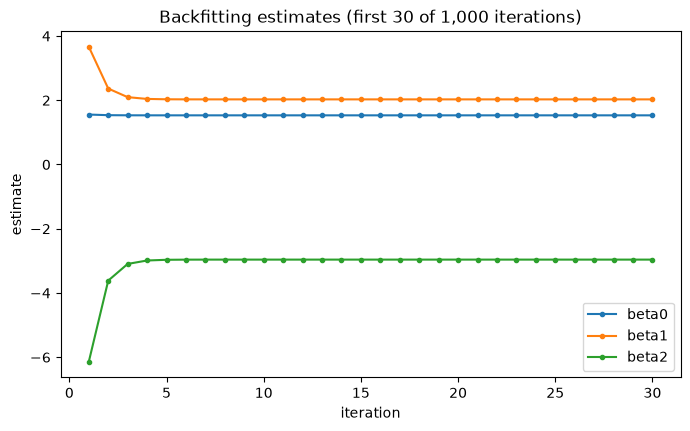

In [21]:
# Exercise 11(f): repeat (d) and (e) 1,000 times, starting again from beta1 = 10.
beta1 = 10.0
history = []
for it in range(1000):
    beta0, beta2 = simple_reg(Y - beta1 * X1, X2)
    beta0, beta1 = simple_reg(Y - beta2 * X2, X1)
    history.append((beta0, beta1, beta2))
history = pd.DataFrame(history, columns=["beta0", "beta1", "beta2"], index=pd.RangeIndex(1, 1001, name="iteration"))
display(history.head(8).round(6))

fig, ax = plt.subplots(figsize=(8, 4.5))
show = history.iloc[:30]
for col, color in zip(history.columns, ["tab:blue", "tab:orange", "tab:green"]):
    ax.plot(show.index, show[col], marker="o", ms=3, color=color, label=col)
ax.set(xlabel="iteration", ylabel="estimate", title="Backfitting estimates (first 30 of 1,000 iterations)")
ax.legend()
plt.show()

### Exercise 11(g)

Compare your answer in (e) to the results of simply performing multiple linear regression to predict Y using X1 and X2.
Use axline() method to overlay those multiple linear regression
coefficient estimates on the plot obtained in (e).

Multiple regression: [ 1.530581  2.027427 -2.96108 ]
Backfitting (iteration 1000): [ 1.530581  2.027427 -2.96108 ]


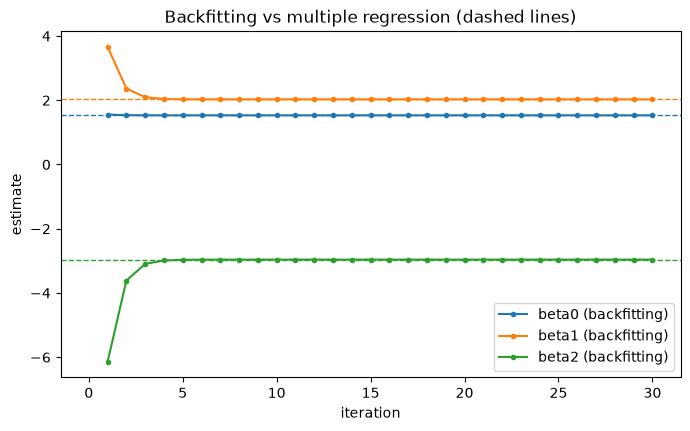

In [22]:
# Exercise 11(g)
mlr = sm.OLS(Y, sm.add_constant(np.column_stack([X1, X2]))).fit()
print("Multiple regression:", mlr.params.round(6))
print("Backfitting (iteration 1000):", history.iloc[-1].values.round(6))

fig, ax = plt.subplots(figsize=(8, 4.5))
for col, color, b in zip(history.columns, ["tab:blue", "tab:orange", "tab:green"], mlr.params):
    ax.plot(show.index, show[col], marker="o", ms=3, color=color, label=f"{col} (backfitting)")
    ax.axline((0, b), slope=0, color=color, ls="--", lw=1)
ax.set(xlabel="iteration", ylabel="estimate", title="Backfitting vs multiple regression (dashed lines)")
ax.legend()
plt.show()

### Exercise 11(h)

On this data set, how many backfitting iterations were required
in order to obtain a “good” approximation to the multiple regression coefficient estimates?

In [23]:
# Exercise 11(h)
err = np.abs(history.to_numpy() - mlr.params).max(axis=1)
for tol in [1e-2, 1e-4, 1e-8]:
    print(f"max |difference| < {tol:g} after {int(np.argmax(err < tol)) + 1} iterations")

max |difference| < 0.01 after 5 iterations
max |difference| < 0.0001 after 8 iterations
max |difference| < 1e-08 after 14 iterations


**Observations / conclusions**

I simulated $Y = 1.5 + 2X_1 - 3X_2 + \varepsilon$ with $\operatorname{corr}(X_1, X_2) \approx 0.45$ and started backfitting from $\beta_1 = 10$, far from the truth. The estimates jump to (1.55, 3.67, −6.14) after one iteration and then converge geometrically. After 1,000 iterations they equal the multiple-regression estimates (1.5306, 2.0274, −2.9611) to six decimals.
**(h)** It takes **about 5 iterations** to get within 0.01 of the OLS coefficients, 8 iterations to get within 1e-4, and 14 iterations to get within 1e-8. The more correlated $X_1$ and $X_2$ are, the slower the convergence. With uncorrelated predictors, one iteration would suffice.

---

## Exercise 12 · Applied

**Textbook: printed page 329**

This problem is a continuation of the previous exercise. In a toy
example with p = 100, show that one can approximate the multiple
linear regression coefficient estimates by repeatedly performing simple
linear regression in a backfitting procedure. How many backfitting
iterations are required in order to obtain a “good” approximation to
the multiple regression coefficient estimates? Create a plot to justify
your answer.

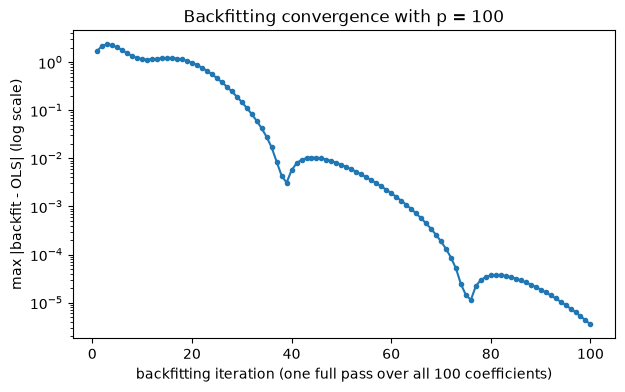

max error < 0.01 after 37 iterations
max error < 0.0001 after 72 iterations
max error < 1e-08 after >100 iterations


In [24]:
# Exercise 12: backfitting with p = 100 predictors.
rng = np.random.default_rng(12)
n, p = 1000, 100
Z = rng.normal(size=(n, p))
Xp = Z + 0.5 * Z[:, [0]]          # shared factor -> correlated predictors
beta_p = rng.normal(size=p)
Yp = 2.0 + Xp @ beta_p + rng.normal(size=n)

mlr_p = sm.OLS(Yp, sm.add_constant(Xp)).fit().params
b0, b = 0.0, np.zeros(p)
max_err = []
for it in range(100):
    for j in range(p):
        partial = Yp - b0 - Xp @ b + b[j] * Xp[:, j]
        _, b[j] = simple_reg(partial, Xp[:, j])
        b0 = np.mean(Yp - Xp @ b)
    max_err.append(np.max(np.abs(np.r_[b0, b] - mlr_p)))
max_err = pd.Series(max_err, index=pd.RangeIndex(1, 101, name="iteration"))

fig, ax = plt.subplots(figsize=(7, 4))
ax.semilogy(max_err.index, max_err.values, marker="o", ms=3)
ax.set(xlabel="backfitting iteration (one full pass over all 100 coefficients)",
       ylabel="max |backfit - OLS| (log scale)", title="Backfitting convergence with p = 100")
plt.show()
for tol in [1e-2, 1e-4, 1e-8]:
    hit = max_err[max_err < tol]
    print(f"max error < {tol:g} after {hit.index.min() if len(hit) else '>100'} iterations")

**Observations / conclusions**

With p = 100 correlated predictors (a shared factor gives every pair a correlation of about 0.2) and n = 1,000, coordinate-wise backfitting still converges to the multiple-regression solution. The plot shows the maximum coefficient error falling roughly geometrically, as a straight line on the log scale. It takes **about 37 full passes** to get within 0.01 of the OLS estimates and about 72 passes to get within 1e-4. So a "good" approximation needs a few dozen iterations here, far more than with p = 2, because correlation among many predictors slows coordinate descent. With independent predictors it would converge almost immediately.